## 1. Cấu hình và tìm dữ liệu

In [8]:
from pathlib import Path
import os, time, json, random, zipfile
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import matplotlib.pyplot as plt
from IPython.display import display

SEED=42
EPOCHS=10
BATCH_SIZE=32
NUM_WORKERS=2
RUN_ADVANCED=False
DATA_ROOT_OVERRIDE=None
OUT=Path('/kaggle/working/DS201_Lab2_Results') if Path('/kaggle').exists() else Path('DS201_Lab2_Results')
OUT.mkdir(parents=True,exist_ok=True)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE)

def locate_data():
    if DATA_ROOT_OVERRIDE:
        p=Path(DATA_ROOT_OVERRIDE)
        if not ((p/'train').is_dir() and (p/'test').is_dir()):raise FileNotFoundError(p)
        return p
    for p in sorted(Path('/kaggle/input').rglob('train')) if Path('/kaggle/input').exists() else []:
        if p.is_dir() and (p.parent/'test').is_dir():return p.parent
    for z in Path('/kaggle/input').rglob('*.zip') if Path('/kaggle/input').exists() else []:
        dst=OUT/'unzipped'
        with zipfile.ZipFile(z) as f:
            for entry in f.infolist():
                path=(dst/entry.filename).resolve()
                if not path.is_relative_to(dst.resolve()):raise ValueError('ZIP chứa đường dẫn không hợp lệ')
            f.extractall(dst)
        for p in dst.rglob('train'):
            if p.is_dir() and (p.parent/'test').is_dir():return p.parent
    raise FileNotFoundError('Chưa Add Input VinaFood21 (cần có train/ và test/).')

DATA_ROOT=locate_data()
print('Dữ liệu:',DATA_ROOT)

Device: cuda
Dữ liệu: /kaggle/input/datasets/huyygiaa/vinafood21/VinaFood21


## 2. DataLoader (cùng split seed 42 cho mọi mô hình)

In [9]:
MEAN=(0.485,0.456,0.406)
STD=(0.229,0.224,0.225)

def loaders(size=64,augment=True):
    ev=transforms.Compose([transforms.Resize((size,size)),transforms.ToTensor(),transforms.Normalize(MEAN,STD)])
    tr=transforms.Compose([transforms.RandomResizedCrop(size,scale=(.7,1.)),
        transforms.RandomHorizontalFlip(),transforms.RandomRotation(15),
        transforms.ColorJitter(.2,.2,.2),transforms.ToTensor(),transforms.Normalize(MEAN,STD)]) if augment else ev
    full=datasets.ImageFolder(DATA_ROOT/'train',transform=tr)
    test=datasets.ImageFolder(DATA_ROOT/'test',transform=ev)
    if len(full.classes)!=21 or full.classes!=test.classes:raise ValueError('Nhãn train/test không trùng 21 lớp')
    if (DATA_ROOT/'val').is_dir():
        train=full
        val=datasets.ImageFolder(DATA_ROOT/'val',transform=ev)
        if val.classes!=full.classes:raise ValueError('Nhãn val khác train')
    else:
        ids=torch.randperm(len(full),generator=torch.Generator().manual_seed(SEED)).tolist()
        n=max(1,int(len(ids)*.1))
        train=Subset(full,ids[n:])
        val=Subset(datasets.ImageFolder(DATA_ROOT/'train',transform=ev),ids[:n])
    kwargs={'batch_size':BATCH_SIZE,'num_workers':NUM_WORKERS,'pin_memory':DEVICE.type=='cuda'}
    return (DataLoader(train,shuffle=True,**kwargs), DataLoader(val,shuffle=False,**kwargs),
            DataLoader(test,shuffle=False,**kwargs),full.classes)

tr,va,te,CLASSES=loaders()
print('Train / Val / Test:',len(tr.dataset),len(va.dataset),len(te.dataset))
print('21 lớp:',CLASSES)

Train / Val / Test: 9040 1004 6682
21 lớp: ['banh-can', 'banh-hoi', 'banh-mi-chao', 'banh-tet', 'banh-trang-tron', 'banh-u', 'banh-uot', 'bap-nuong', 'bo-kho', 'bo-la-lot', 'bot-chien', 'ca-ri', 'canh-kho-qua', 'canh-khoai-mo', 'ga-nuong', 'goi-ga', 'ha-cao', 'hoanh-thanh-nuoc', 'pha-lau', 'tau-hu', 'thit-kho-trung']


## 3. Mô hình LeNet-5 và GoogLeNet rút gọn

In [10]:
class LeNet5(nn.Module):
    def __init__(self,pool='avg'):
        super().__init__()
        Pool=nn.AvgPool2d if pool=='avg' else nn.MaxPool2d
        self.c1=nn.Conv2d(3,6,5); self.s2=Pool(2)
        self.c3=nn.Conv2d(6,16,5); self.s4=Pool(2)
        self.f5=nn.Linear(2704,120);self.f6=nn.Linear(120,84);self.out=nn.Linear(84,21)
    def forward(self,x):
        x=self.s2(F.relu(self.c1(x)))
        x=self.s4(F.relu(self.c3(x)))
        return self.out(F.relu(self.f6(F.relu(self.f5(x.flatten(1))))))

class Inception(nn.Module):
    def __init__(self,c,f1,f3r,f3,f5r,f5,fp):
        super().__init__()
        self.b1=nn.Sequential(nn.Conv2d(c,f1,1),nn.ReLU())
        self.b2=nn.Sequential(nn.Conv2d(c,f3r,1),nn.ReLU(),nn.Conv2d(f3r,f3,3,padding=1),nn.ReLU())
        self.b3=nn.Sequential(nn.Conv2d(c,f5r,1),nn.ReLU(),nn.Conv2d(f5r,f5,5,padding=2),nn.ReLU())
        self.b4=nn.Sequential(nn.MaxPool2d(3,1,1),nn.Conv2d(c,fp,1),nn.ReLU())
        self.out_channels=f1+f3+f5+fp
    def forward(self,x):
        return torch.cat([self.b1(x),self.b2(x),self.b3(x),self.b4(x)],1)

class MiniGoogLeNet(nn.Module):
    def __init__(self):
        super().__init__()
        cfg=[(3,16,16,24,4,8,8),(56,32,32,48,8,16,16),
             (112,48,48,64,16,24,24),(160,64,64,96,24,32,32)]
        self.blocks=nn.ModuleList([Inception(*c) for c in cfg])
        self.pool=nn.MaxPool2d(2)
        self.gap=nn.AdaptiveAvgPool2d(1)
        self.fc=nn.Linear(224,21)
    def forward(self,x):
        for i,b in enumerate(self.blocks):
            x=b(x)
            if i<2:x=self.pool(x)
        return self.fc(self.gap(x).flatten(1))

count=lambda m:sum(p.numel() for p in m.parameters())
print('LeNet-5:',count(LeNet5()),'| GoogLeNet:',count(MiniGoogLeNet()))
print('Inception channels:',[b.out_channels for b in MiniGoogLeNet().blocks])
assert count(LeNet5())==339421

LeNet-5: 339421 | GoogLeNet: 188245
Inception channels: [56, 112, 160, 224]


## 4. Huấn luyện, chọn checkpoint bằng validation F1, đánh giá test

In [11]:
def predict(model,dl):
    model.eval();ys=[];ps=[];loss=0.;n=0
    with torch.no_grad():
        for x,y in dl:
            x=x.to(DEVICE);y=y.to(DEVICE)
            logits=model(x)
            loss+=F.cross_entropy(logits,y,reduction='sum').item();n+=len(y)
            ys.extend(y.cpu().numpy());ps.extend(logits.argmax(1).cpu().numpy())
    return loss/n,np.array(ys),np.array(ps)

def scores(y,p):
    prec,rec,f1,_=precision_recall_fscore_support(y,p,labels=range(21),average='macro',zero_division=0)
    return {'accuracy':accuracy_score(y,p),'precision_macro':prec,'recall_macro':rec,'f1_macro':f1}

def run(name,model,size=64,augment=True,lr=.001,epochs=EPOCHS):
    train_dl,val_dl,test_dl,classes=loaders(size,augment)
    model=model.to(DEVICE)
    opt=torch.optim.Adam((p for p in model.parameters() if p.requires_grad),lr=lr)
    folder=OUT/name;folder.mkdir(exist_ok=True)
    hist=[];best=-1;best_epoch=0
    print(f'\n{name}: train={len(train_dl.dataset)}, val={len(val_dl.dataset)}, test={len(test_dl.dataset)}',flush=True)
    for ep in range(1,epochs+1):
        start=time.perf_counter();model.train();total=0;loss_sum=0
        for x,y in train_dl:
            x=x.to(DEVICE);y=y.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss=F.cross_entropy(model(x),y)
            loss.backward();opt.step()
            total+=len(y);loss_sum+=loss.item()*len(y)
        val_loss,y,p=predict(model,val_dl)
        f1=scores(y,p)['f1_macro']
        seconds=time.perf_counter()-start
        hist.append({'epoch':ep,'train_loss':loss_sum/total,'val_loss':val_loss,'val_f1':f1,'seconds':seconds})
        if f1>best:
            best=f1;best_epoch=ep
            torch.save(model.state_dict(),folder/'best.pt')
        print(f'{name} {ep:02d}/{epochs}: loss={loss_sum/total:.4f}, val_loss={val_loss:.4f}, val_F1={f1:.4f}, {seconds:.1f}s',flush=True)
    model.load_state_dict(torch.load(folder/'best.pt',map_location=DEVICE,weights_only=True))
    _,y,p=predict(model,test_dl)
    metrics={k:float(v) for k,v in scores(y,p).items()}
    metrics.update({'model':name,'params':count(model),'img_size':size,'seconds_per_epoch':float(np.mean([h['seconds'] for h in hist])),
                    'best_epoch':best_epoch,'best_val_f1':float(best)})
    per=precision_recall_fscore_support(y,p,labels=range(21),zero_division=0)
    byclass=pd.DataFrame({'class':classes,'precision':per[0],'recall':per[1],'f1':per[2],'support':per[3]})
    cm=confusion_matrix(y,p,labels=range(21))
    pd.DataFrame(hist).to_csv(folder/'history.csv',index=False)
    byclass.to_csv(folder/'per_class_f1.csv',index=False)
    pd.DataFrame(cm,index=classes,columns=classes).to_csv(folder/'confusion_matrix.csv')
    (folder/'metrics.json').write_text(json.dumps(metrics,indent=2,ensure_ascii=False),encoding='utf-8')
    return metrics,pd.DataFrame(hist),byclass,cm

## 5. Bài 1–2 bắt buộc: chạy 3 thí nghiệm

In [12]:
experiments=[('lenet_avg',LeNet5('avg')),('lenet_max',LeNet5('max')),('googlenet',MiniGoogLeNet())]
results={}
for name,model in experiments:
    results[name]=run(name,model)

summary=pd.DataFrame([v[0] for v in results.values()])
cols=['model','params','img_size','seconds_per_epoch','accuracy','precision_macro','recall_macro','f1_macro','best_epoch']
display(summary[cols].round(4))
summary.to_csv(OUT/'summary.csv',index=False)


lenet_avg: train=9040, val=1004, test=6682


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_avg 01/10: loss=2.8851, val_loss=2.7541, val_F1=0.0747, 750.4s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


lenet_avg 02/10: loss=2.7116, val_loss=2.5781, val_F1=0.1207, 85.1s


...

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


googlenet 09/10: loss=1.9726, val_loss=1.9410, val_F1=0.3331, 86.2s


/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


googlenet 10/10: loss=1.9447, val_loss=1.8557, val_F1=0.3635, 84.8s


,model,params,img_size,seconds_per_epoch,accuracy,precision_macro,recall_macro,f1_macro,best_epoch
0,lenet_avg,339421,64,151.9697,0.2781,0.2776,0.2606,0.2513,9
1,lenet_max,339421,64,85.0898,0.3156,0.3023,0.3046,0.2916,10
2,googlenet,188245,64,85.2997,0.3568,0.3716,0.3316,0.3172,10


## 6. Bảng F1 từng lớp, loss curves và confusion matrix


### lenet_avg | Test accuracy: 0.2781 | Macro F1: 0.2513


,class,precision,recall,f1,support
0,banh-can,0.1898,0.2158,0.2019,241
1,banh-hoi,0.3408,0.3015,0.3199,607
2,banh-mi-chao,0.1986,0.3010,0.2393,289
3,banh-tet,0.2618,0.1676,0.2044,364
4,banh-trang-tron,0.2400,0.0971,0.1382,309
5,banh-u,0.1833,0.0625,0.0932,176
6,banh-uot,0.2826,0.2518,0.2663,560
7,bap-nuong,0.2500,0.0070,0.0136,143
8,bo-kho,0.2757,0.3254,0.2985,338
9,bo-la-lot,0.4636,0.5983,0.5224,458


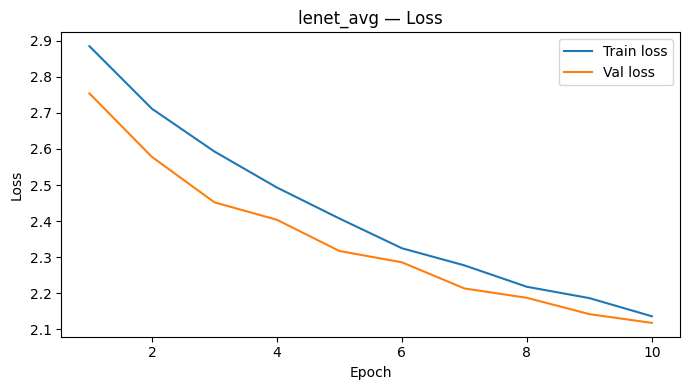

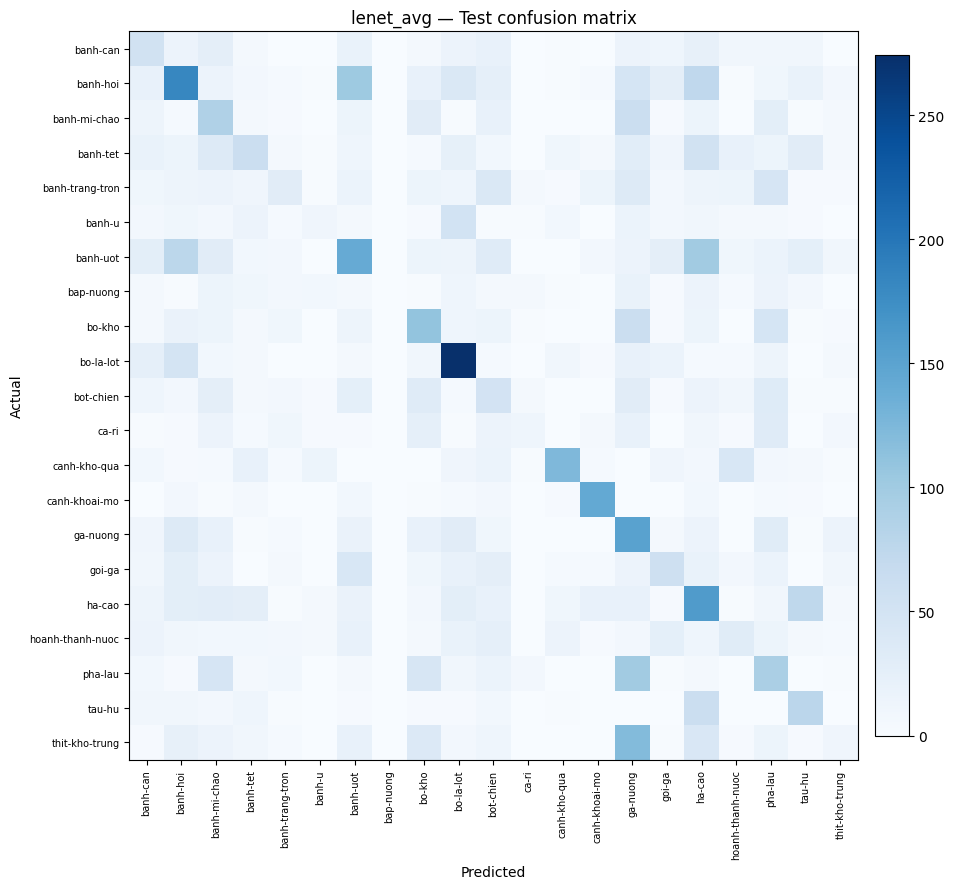


### lenet_max | Test accuracy: 0.3156 | Macro F1: 0.2916


,class,precision,recall,f1,support
0,banh-can,0.2299,0.1660,0.1928,241
1,banh-hoi,0.3538,0.3410,0.3473,607
2,banh-mi-chao,0.2731,0.4913,0.3511,289
3,banh-tet,0.3866,0.2527,0.3056,364
4,banh-trang-tron,0.1923,0.0971,0.1290,309
5,banh-u,0.2128,0.1136,0.1481,176
6,banh-uot,0.3163,0.3214,0.3189,560
7,bap-nuong,0.1449,0.0699,0.0943,143
8,bo-kho,0.2980,0.3491,0.3215,338
9,bo-la-lot,0.4498,0.6463,0.5305,458


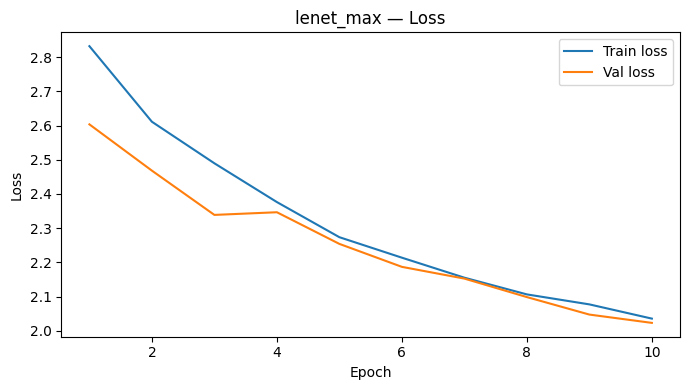

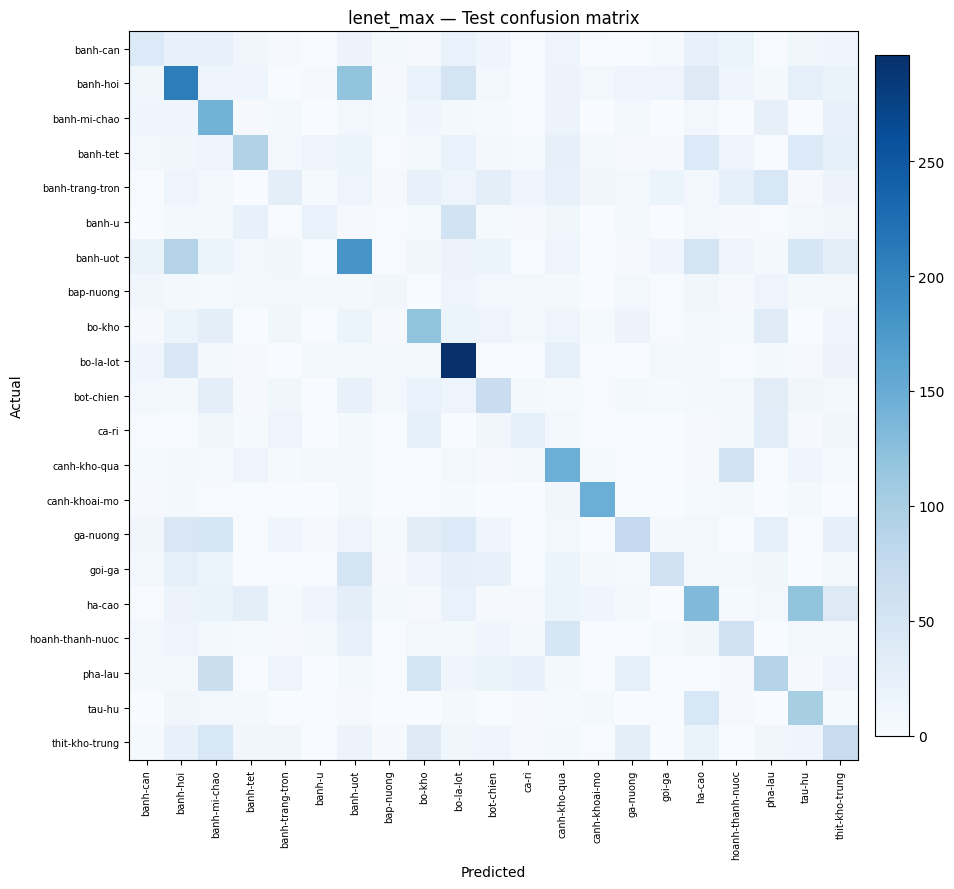


### googlenet | Test accuracy: 0.3568 | Macro F1: 0.3172


,class,precision,recall,f1,support
0,banh-can,0.3371,0.1245,0.1818,241
1,banh-hoi,0.4897,0.4679,0.4785,607
2,banh-mi-chao,0.3014,0.5225,0.3823,289
3,banh-tet,0.5000,0.4093,0.4502,364
4,banh-trang-tron,0.1214,0.0550,0.0757,309
5,banh-u,0.5357,0.1705,0.2586,176
6,banh-uot,0.3863,0.3732,0.3797,560
7,bap-nuong,0.4444,0.0280,0.0526,143
8,bo-kho,0.2905,0.3876,0.3321,338
9,bo-la-lot,0.4071,0.8319,0.5466,458


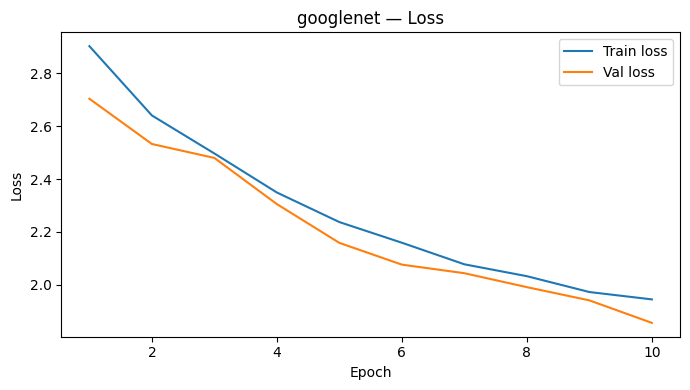

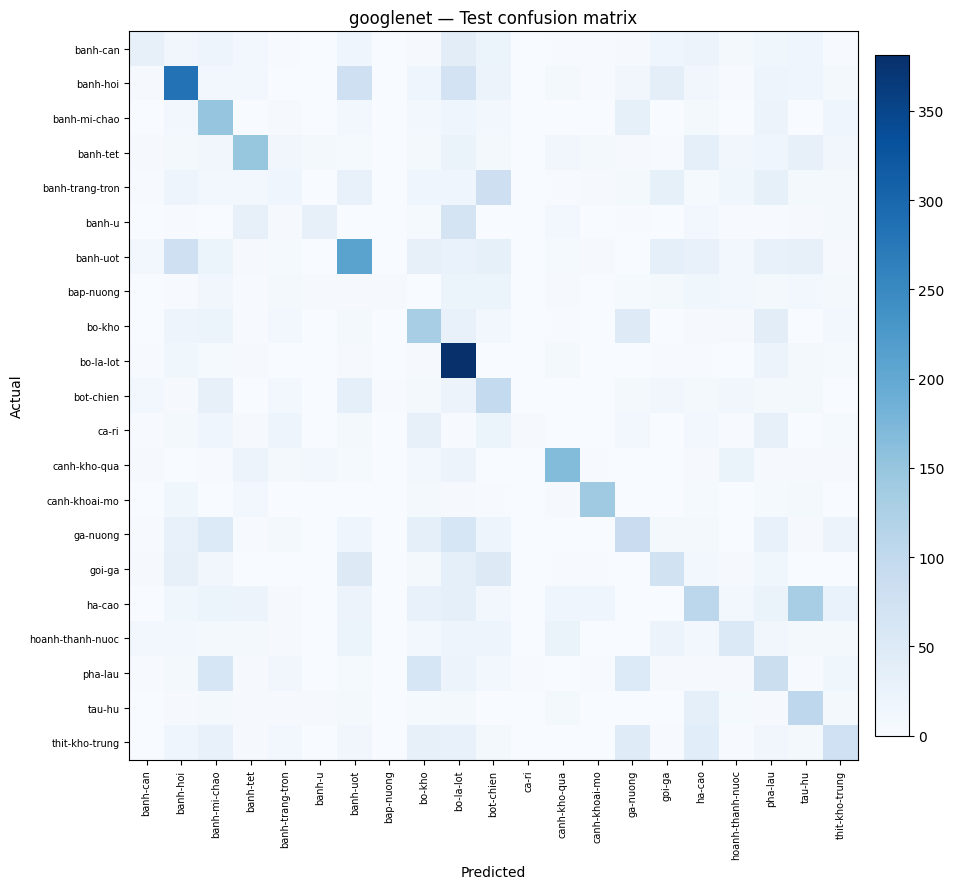


SO SÁNH:
MaxPool - AvgPool (macro-F1): 0.0403
GoogLeNet - LeNet AvgPool (macro-F1): 0.0659
Tham số GoogLeNet/LeNet: 0.55
Giây/epoch GoogLeNet/LeNet: 0.56
Lưu kết quả tại: /kaggle/working/DS201_Lab2_Results


In [13]:
for name,(metric,hist,byclass,cm) in results.items():
    print('\n###',name,'| Test accuracy:',round(metric['accuracy'],4),'| Macro F1:',round(metric['f1_macro'],4))
    display(byclass.round(4))
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(hist['epoch'],hist['train_loss'],label='Train loss')
    ax.plot(hist['epoch'],hist['val_loss'],label='Val loss')
    ax.set(title=f'{name} — Loss',xlabel='Epoch',ylabel='Loss');ax.legend()
    fig.tight_layout();fig.savefig(OUT/name/'loss_curve.png',dpi=140);plt.show()
    fig,ax=plt.subplots(figsize=(10,9))
    image=ax.imshow(cm,cmap='Blues')
    ax.set_xticks(range(21),CLASSES,rotation=90,fontsize=7)
    ax.set_yticks(range(21),CLASSES,fontsize=7)
    ax.set(title=f'{name} — Test confusion matrix',xlabel='Predicted',ylabel='Actual')
    fig.colorbar(image,ax=ax,fraction=.04,pad=.02)
    fig.tight_layout();fig.savefig(OUT/name/'confusion_matrix.png',dpi=140);plt.show()

avg,maxp,goo=[results[x][0] for x in ['lenet_avg','lenet_max','googlenet']]
print('\nSO SÁNH:')
print('MaxPool - AvgPool (macro-F1):',round(maxp['f1_macro']-avg['f1_macro'],4))
print('GoogLeNet - LeNet AvgPool (macro-F1):',round(goo['f1_macro']-avg['f1_macro'],4))
print('Tham số GoogLeNet/LeNet:',round(goo['params']/avg['params'],2))
print('Giây/epoch GoogLeNet/LeNet:',round(goo['seconds_per_epoch']/avg['seconds_per_epoch'],2))
print('Lưu kết quả tại:',OUT)